# 2.2 - Entrenamiento de una red neuronal para regresión

Vamos a predecir las **calorías consumidas al correr** a partir de tres variables:

| Variable | Papel | Unidad |
| --- | --- | --- |
| Tiempo | Entrada $x_1$ | minutos |
| Peso | Entrada $x_2$ | kg |
| Velocidad | Entrada $x_3$ | km/h |
| Calorías | Objetivo $y$ | kcal |

Seguiremos el ejemplo del apartado 2 del notebook **6_01_02_Redes_Neuronales_Regresion_TensorFlow.ipynb**, con la arquitectura que aparece en su código: **3 entradas, dos capas ocultas de 32 y 16 neuronas ReLU y una salida lineal**.

1. Cargar los datos.
2. Separar entrenamiento y test.
3. Normalizar las entradas.
4. Definir la arquitectura.
5. Diseñar la pérdida y elegir el optimizador.
6. Entrenar y registrar la evolución de entrenamiento y test.
7. Representar pérdida, MAE y MSE en **tres gráficas independientes**.
8. Predecir las calorías para **32 minutos, 75 kg y 11 km/h**.

**Orden del preprocesado:** separamos antes de normalizar. El escalador aprende mínimos y máximos solo del entrenamiento. Trabajamos con dos conjuntos, **entrenamiento y test**, sin reservar un tercer conjunto de validación.

Ejecuta las celdas en orden con el entorno Python de la asignatura. Se utilizan TensorFlow/Keras, pandas, NumPy, scikit-learn y Matplotlib.

---
## 1. Carga y exploración de los datos

El CSV de la asignatura contiene 5.000 observaciones. Mostramos cinco filas y conservamos una copia de los valores originales para poder interpretar las unidades.

In [1]:
from pathlib import Path
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import Callback

SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})
pd.options.display.float_format = "{:,.4f}".format

# Funciona al abrir Jupyter desde MUIA_RNMU o desde la carpeta de materiales.
rutas = [
    Path("datasets/calories_time_weight_speed.csv"),
    Path("MUIA_RNMU/datasets/calories_time_weight_speed.csv"),
]
ruta_csv = next((p for p in rutas if p.is_file()), None)
if ruta_csv is None:
    raise FileNotFoundError("Abre el notebook desde MUIA_RNMU o desde su carpeta superior.")

df = pd.read_csv(ruta_csv)
features_cols = ["Tiempo", "Peso", "Velocidad"]
target_col = "Calorias"
display(df[features_cols + [target_col]].head(5))
print(f"Dataset: {len(df):,} observaciones; {len(features_cols)} entradas y un objetivo.")
print("Valores ausentes por columna:")
display(df[features_cols + [target_col]].isna().sum().to_frame("Ausentes"))

,Tiempo,Peso,Velocidad,Calorias
0,13.7000,61.2000,12.3000,177.9000
1,51.9000,62.6000,11.5000,644.1000
2,55.4000,69.3000,14.0000,929.4000
3,61.9000,80.1000,11.0000,941.2000
4,19.9000,95.6000,9.2000,303.1000


Dataset: 5,000 observaciones; 3 entradas y un objetivo.
Valores ausentes por columna:


,Ausentes
Tiempo,0
Peso,0
Velocidad,0
Calorias,0


---
## 2. Partición en entrenamiento y test

**X** contiene Tiempo, Peso y Velocidad, en ese orden. **y** contiene Calorias.

Reservamos el **80 % para entrenamiento** y el **20 % para test**. `random_state=0` mantiene la misma partición que el ejemplo de la presentación. Las 4.000 observaciones de entrenamiento ajustarán los pesos; las 1.000 de test no participan en las actualizaciones.

In [2]:
X = df[features_cols].copy()
y = df[target_col].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

display(pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Test"],
    "Observaciones": [len(X_train), len(X_test)],
    "Porcentaje": [80, 20],
}))
print("Primeras cinco observaciones de entrenamiento, sin normalizar:")
display(X_train.head(5))

,Conjunto,Observaciones,Porcentaje
0,Entrenamiento,4000,80
1,Test,1000,20


Primeras cinco observaciones de entrenamiento, sin normalizar:


,Tiempo,Peso,Velocidad
2913,57.0000,68.8000,14.4000
3275,51.1000,69.7000,9.4000
775,32.7000,77.8000,10.1000
217,5.1000,68.8000,15.6000
1245,85.1000,63.2000,9.0000


---
## 3. Normalización de las entradas

Tiempo, Peso y Velocidad tienen escalas diferentes. Aplicamos **MinMaxScaler**, por separado a cada variable:

$$x_j' = \frac{x_j-\min(X_{train,j})}{\max(X_{train,j})-\min(X_{train,j})}$$

* `fit_transform(X_train)` calcula los mínimos y máximos y normaliza entrenamiento.
* `transform(X_test)` reutiliza esos mismos valores en test.
* El objetivo **y se mantiene en kcal**, sin normalizar.

Los datos de entrenamiento quedan en [0, 1]. Un dato nuevo o de test puede quedar fuera de ese intervalo si supera los extremos observados en entrenamiento.

In [3]:
scaler = MinMaxScaler()
X_train_n = scaler.fit_transform(X_train).astype("float32")
X_test_n = scaler.transform(X_test).astype("float32")

# Conservamos el orden de las filas y una dimensión de salida compatible con Keras.
y_train_array = y_train.to_numpy(dtype="float32")
y_test_array = y_test.to_numpy(dtype="float32")

extremos = pd.DataFrame({
    "Variable": features_cols,
    "Mínimo de entrenamiento": scaler.data_min_,
    "Máximo de entrenamiento": scaler.data_max_,
})
display(extremos)

comparacion = pd.concat({
    "Original": X_train.head(5),
    "Normalizado": pd.DataFrame(
        X_train_n[:5], columns=features_cols, index=X_train.index[:5]
    ),
}, axis=1)
display(comparacion)

,Variable,Mínimo de entrenamiento,Máximo de entrenamiento
0,Tiempo,4.0000,99.0000
1,Peso,32.5000,102.3000
2,Velocidad,9.0000,16.0000


Original                   Normalizado                 
       Tiempo    Peso Velocidad      Tiempo   Peso Velocidad
2913  57.0000 68.8000   14.4000      0.5579 0.5201    0.7714
3275  51.1000 69.7000    9.4000      0.4958 0.5330    0.0571
775   32.7000 77.8000   10.1000      0.3021 0.6490    0.1571
217    5.1000 68.8000   15.6000      0.0116 0.5201    0.9429
1245  85.1000 63.2000    9.0000      0.8537 0.4398    0.0000

---
## 4. Arquitectura de la red neuronal

```text
Tiempo ───┐
Peso ─────┼── 32 neuronas ReLU ── 16 neuronas ReLU ── 1 neurona lineal ── Calorías
Velocidad ┘
```

* **Entrada:** tres valores normalizados, uno por variable.
* **Dos capas ocultas densas:** 32 y 16 neuronas, con activación ReLU. Cada neurona tiene su bias.
* **Salida:** una neurona lineal, adecuada para un único objetivo continuo.
* **Parámetros entrenables:** $(3+1)\times32+(32+1)\times16+(16+1)\times1=673$.

Usamos `Input(shape=(3,))` para declarar las entradas de forma explícita. Es la misma arquitectura que la del ejemplo con `input_dim=3`.

In [4]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEMILLA)

model = Sequential([
    Input(shape=(3,), name="entradas"),
    Dense(32, activation="relu", name="oculta_1"),
    Dense(16, activation="relu", name="oculta_2"),
    Dense(1, activation="linear", name="calorias"),
], name="MLP_calorias")

model.summary()

Model: "MLP_calorias"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                     │ (None, 32)                  │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ oculta_2 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ calorias (Dense)                     │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 673 (2.63 KB)

 Trainable params: 673 (2.63 KB)

 Non-trainable params: 0 (0.00 B)

---
## 5. Función de pérdida y elección del optimizador

Utilizamos **MSE** como pérdida y **Adam** para actualizar los pesos y los bias.

$$MSE = \frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2$$

También registramos el **error absoluto medio (MAE)**:

$$MAE = \frac{1}{N}\sum_{i=1}^{N}|y_i-\hat{y}_i|$$

| Magnitud | Qué representa | Unidad |
| --- | --- | --- |
| Pérdida (`loss`) | Objetivo que minimiza el optimizador: MSE | kcal² |
| Error (`mae`) | Diferencia absoluta media entre valor real y predicho | kcal |
| Error cuadrático medio (`mse`) | Diferencia cuadrática media registrada como métrica | kcal² |

**La pérdida y MSE coinciden en este modelo**, porque la pérdida es MSE y no añadimos términos de regularización. Aun así, los mostraremos en dos gráficas distintas, además de la de MAE. Así distinguimos el papel de la pérdida del de una métrica.

In [5]:
LEARNING_RATE = 0.001
EPOCHS = 50
BATCH_SIZE = 16

loss_fn = tf.keras.losses.MeanSquaredError()
optimizer = Adam(learning_rate=LEARNING_RATE)

model.compile(
    loss=loss_fn,
    optimizer=optimizer,
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="mae"),
        tf.keras.metrics.MeanSquaredError(name="mse"),
    ],
)

---
## 6. Entrenamiento y seguimiento por época

Entrenaremos durante **100 épocas**, con lotes de **16 observaciones**. Cada época recorre todo el conjunto de entrenamiento.

Para las gráficas registraremos las métricas de **los dos conjuntos al finalizar cada época, usando los mismos pesos ya actualizados**. Una pequeña función de seguimiento (`Callback`) hace las predicciones y guarda pérdida, MAE y MSE.

El test se observa con un fin didáctico: **no actualiza pesos y no se utiliza para seleccionar épocas ni hiperparámetros**. No hay un tercer conjunto ni se pasa `validation_data` a `fit`. En un desarrollo real, si las decisiones se toman mirando estas curvas de test, ese conjunto deja de servir como evaluación final independiente.

Las métricas de entrenamiento que registra `fit` promedian los lotes mientras los pesos están cambiando. Por eso pueden diferir ligeramente de las métricas que calculamos aquí sobre el entrenamiento completo al acabar cada época.

In [6]:
class SeguimientoPorEpoch(Callback):
    def __init__(self, X_train, y_train, X_test, y_test):
        super().__init__()
        self.conjuntos = {
            "train": (X_train, y_train),
            "test": (X_test, y_test),
        }
        self.registros = []

    def on_train_begin(self, logs=None):
        self.registros = []

    def on_epoch_end(self, epoch, logs=None):
        fila = {"epoch": epoch + 1}
        for nombre, (entradas, reales) in self.conjuntos.items():
            # training=False: solo inferencia, sin actualización de pesos.
            predichas = self.model(entradas, training=False).numpy().ravel()
            fila[f"loss_{nombre}"] = float(loss_fn(
                reales.reshape(-1, 1), predichas.reshape(-1, 1)
            ).numpy())
            fila[f"mae_{nombre}"] = mean_absolute_error(reales, predichas)
            fila[f"mse_{nombre}"] = mean_squared_error(reales, predichas)
        self.registros.append(fila)
        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch + 1:3d}/{self.params['epochs']} | "
                f"MSE train: {fila['mse_train']:10.4f} | "
                f"MSE test: {fila['mse_test']:10.4f} | "
                f"MAE test: {fila['mae_test']:8.4f} kcal"
            )

seguimiento = SeguimientoPorEpoch(
    X_train_n, y_train_array, X_test_n, y_test_array
)

In [7]:
history = model.fit(
    X_train_n,
    y_train_array,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    callbacks=[seguimiento],
    verbose=0,
)

evolucion = pd.DataFrame(seguimiento.registros).set_index("epoch")
display(evolucion.tail(5))

Epoch   1/50 | MSE train: 395334.3438 | MSE test: 399588.4062 | MAE test: 549.7717 kcal
Epoch  10/50 | MSE train: 16019.4873 | MSE test: 16709.0352 | MAE test: 107.3689 kcal
Epoch  20/50 | MSE train:  3678.7466 | MSE test:  3927.0610 | MAE test:  45.5275 kcal
Epoch  30/50 | MSE train:  2306.3142 | MSE test:  2456.4045 | MAE test:  36.3141 kcal
Epoch  40/50 | MSE train:  1129.8427 | MSE test:  1203.6691 | MAE test:  24.2709 kcal
Epoch  50/50 | MSE train:   517.7354 | MSE test:   569.6794 | MAE test:  17.2887 kcal


,loss_train,mae_train,mse_train,loss_test,mae_test,mse_test
epoch,,,,,,
46,681.0573,18.6811,681.0573,739.5327,19.4991,739.5327
47,631.3456,18.0431,631.3456,686.3682,18.8457,686.3682
48,588.4165,17.4610,588.4165,641.8839,18.2769,641.8839
49,550.4260,16.9320,550.4260,603.0435,17.7702,603.0435
50,517.7354,16.4521,517.7354,569.6794,17.2887,569.6794


---
## 7. Evolución del aprendizaje: tres gráficas

Cada figura contiene dos curvas: **azul para entrenamiento** y **rojo para test**. Se muestran todas las épocas, sin eliminar los valores iniciales ni aplicar promedios acumulados.

Las curvas no tienen por qué disminuir en cada época. Comparamos entrenamiento y test para observar cómo evoluciona el error en datos que no ajustan los pesos.

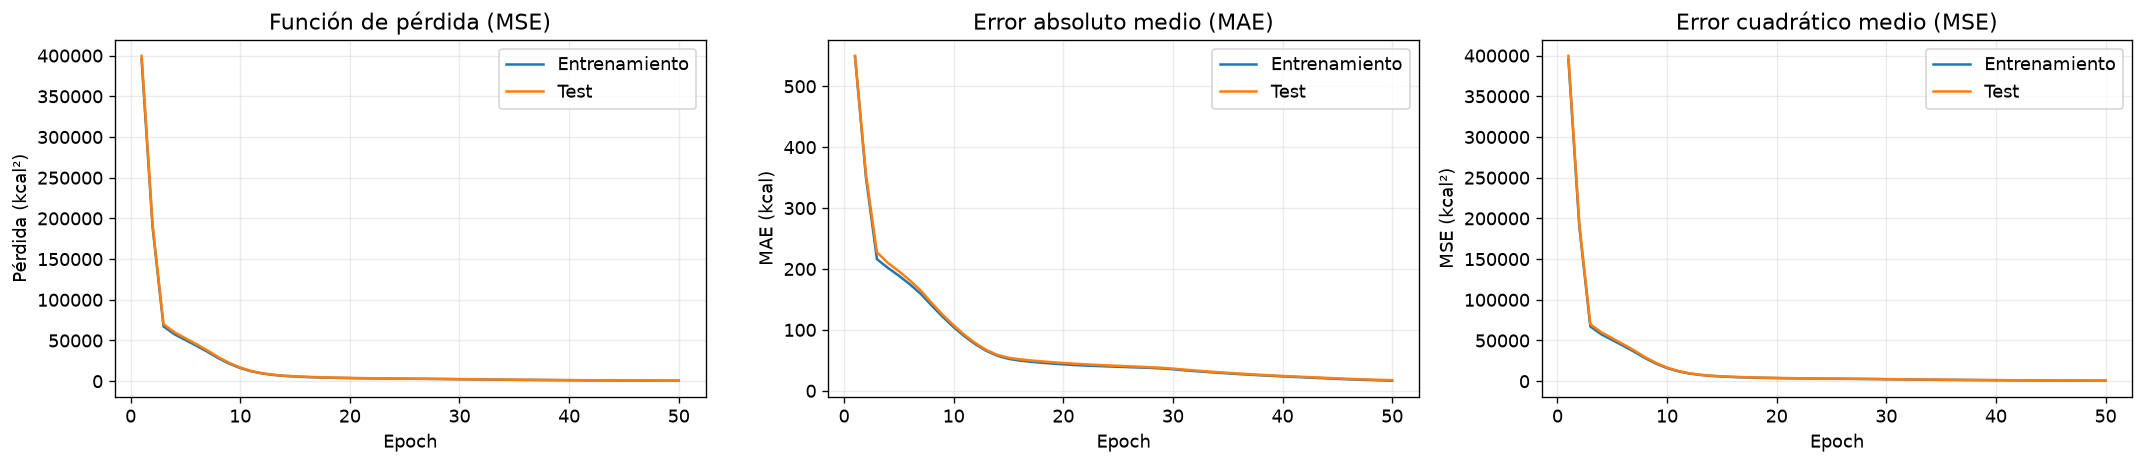

In [8]:
def representar_evolucion(ax, metrica, titulo, unidad):
    ax.plot(evolucion.index, evolucion[f"{metrica}_train"], label="Entrenamiento")
    ax.plot(evolucion.index, evolucion[f"{metrica}_test"], label="Test")
    ax.set(title=titulo, xlabel="Epoch", ylabel=unidad)
    ax.grid(alpha=0.25)
    ax.legend()


fig, axes = plt.subplots(1, 3, figsize=(18, 4))

representar_evolucion(axes[0], "loss", "Función de pérdida (MSE)", "Pérdida (kcal²)")
representar_evolucion(axes[1], "mae", "Error absoluto medio (MAE)", "MAE (kcal)")
representar_evolucion(axes[2], "mse", "Error cuadrático medio (MSE)", "MSE (kcal²)")

fig.tight_layout()
plt.show()

---
## 8. Evaluación del modelo entrenado

Calculamos las métricas una vez finalizado el entrenamiento. El MAE expresa el error medio en kcal y el MSE da más peso a las diferencias grandes. Ambos se calculan con las mismas predicciones finales utilizadas para registrar la última época.

In [9]:
pred_train = model.predict(X_train_n, verbose=0).ravel()
pred_test = model.predict(X_test_n, verbose=0).ravel()

resultados = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Test"],
    "MAE (kcal)": [
        mean_absolute_error(y_train_array, pred_train),
        mean_absolute_error(y_test_array, pred_test),
    ],
    "MSE (kcal²)": [
        mean_squared_error(y_train_array, pred_train),
        mean_squared_error(y_test_array, pred_test),
    ],
})
display(resultados)

,Conjunto,MAE (kcal),MSE (kcal²)
0,Entrenamiento,16.4521,517.7354
1,Test,17.2887,569.6794


---
## 9. Predicción para una persona que sale a correr

Queremos estimar las calorías de una persona que corre durante **32 minutos**, pesa **75 kg** y mantiene una velocidad de **11 km/h**.

1. Construimos una fila con el mismo orden de columnas: Tiempo, Peso y Velocidad.
2. La transformamos con el **escalador ya ajustado**. No volvemos a ejecutar `fit`.
3. Llamamos a `model.predict`.

Como el objetivo no se normalizó, la predicción ya está expresada en **kcal**. Es una estimación del modelo aprendido a partir del dataset, no un valor real conocido para esa persona.

In [10]:
persona = pd.DataFrame({
    "Tiempo": [32.0],
    "Peso": [75.0],
    "Velocidad": [11.0],
})[features_cols]

persona_n = scaler.transform(persona).astype("float32")
calorias_estimadas = float(model.predict(persona_n, verbose=0)[0, 0])

print("Datos originales:")
display(persona)
print("Entradas normalizadas con el escalador de entrenamiento:")
display(pd.DataFrame(persona_n, columns=features_cols))
print(f"Calorías estimadas para 32 min, 75 kg y 11 km/h: {calorias_estimadas:.2f} kcal")

Datos originales:


,Tiempo,Peso,Velocidad
0,32.0000,75.0000,11.0000


Entradas normalizadas con el escalador de entrenamiento:


,Tiempo,Peso,Velocidad
0,0.2947,0.6089,0.2857


Calorías estimadas para 32 min, 75 kg y 11 km/h: 460.07 kcal
